In [ ]:
import os
import subprocess
import sys
from pathlib import Path

SRC = Path.cwd().parent / "src"   # the notebook is in notebooks/, minimal.py is in src/

def run(script, *args):
    """Runs a script from src/, showing its output live.
    Interrupting the cell (■ button / Interrupt) kills the process and all its children."""
    cmd = [sys.executable, "-u", script, *args]   # -u: unbuffered output
    flags = subprocess.CREATE_NEW_PROCESS_GROUP if os.name == "nt" else 0
    proc = subprocess.Popen(
        cmd,
        cwd=SRC,
        stdin=subprocess.PIPE,                    # minimal.py expects input(); keep stdin open
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT,                 # logging goes to stderr: merge it with stdout
        text=True,
        bufsize=1,
        creationflags=flags,
        start_new_session=(os.name != "nt"),
    )
    try:
        for line in proc.stdout:
            print(line, end="", flush=True)
        proc.wait()
    except KeyboardInterrupt:
        print("\n[Interrupted: stopping the process...]")
    finally:
        if proc.poll() is None:
            if os.name == "nt":
                subprocess.run(["taskkill", "/F", "/T", "/PID", str(proc.pid)],
                               stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
            else:
                import signal
                os.killpg(proc.pid, signal.SIGKILL)
            proc.wait()
        print(f"[Process finished, exit code {proc.returncode}]")


# Práctica InterCom: Análisis Experimental del Módulo `minimal.py`

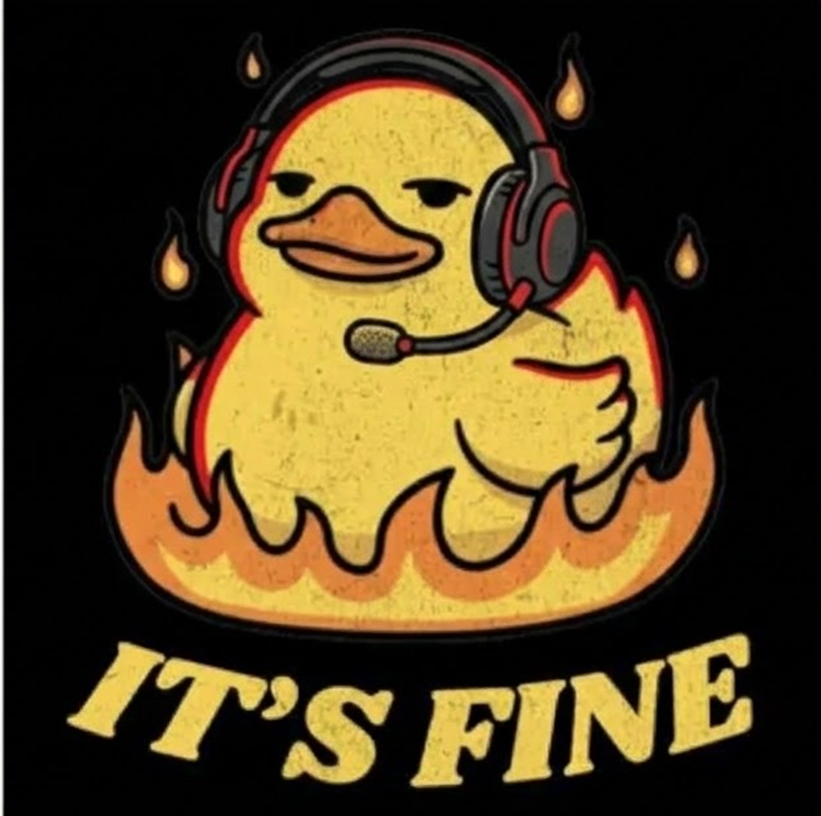

### 👥 Integrantes del Grupo:
* JAVIER RODRÍGUEZ GALLEGOS
* ROCÍO LU GONZÁLEZ PÉREZ
* MARCOS GALLEGO PÉREZ
* ANDRES XANDRI LÓPEZ

---


### Experimento 1: Configuración por Defecto en Local (`localhost`)
**Enunciado:** Ejecuta `minimal.py` utilizando localhost como destino para tus fragmentos de audio. Comprueba que puedes escucharte a ti mismo después de cierto retraso y que la calidad del sonido sea buena. Determina el retraso, si es posible, experimentalmente empleando los modificadores `--show_stats`, `--show_samples` y `--show_spectrum`.


#### Comando ejecutado en la terminal:
##### python minimal.py --show_stats --show_samples --show_spectrum


#### Capturas de la Consola:
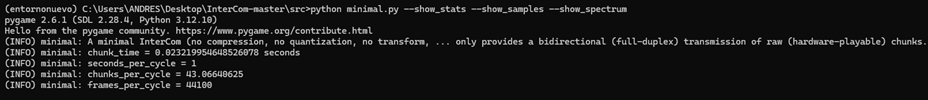
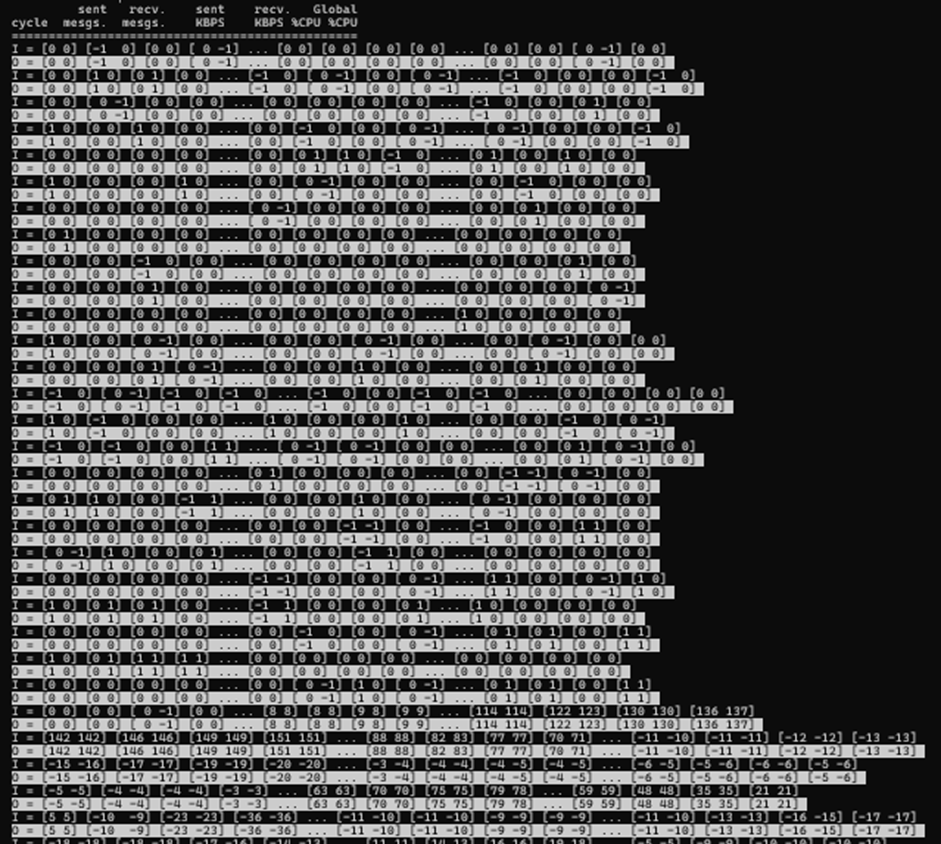

#### Conclusiones Extraídas:
* **Calidad de Sonido:** Aunque no se haga uso de auriculares, la calidad del sonido es limpia y buena, sin cortes ni distorsiones notables. No se aprecian artefactos digitales debido a que la transmisión se realiza en crudo (RAW) a 44100 Hz en estéreo y sin compresión dentro de la propia máquina (localhost).
* **Modificador `--show_stats`:** Permite monitorizar el rendimiento de la red y el consumo de CPU ciclo a ciclo. Al estar en local, la tasa de envío y recepción es idéntica (43 bloques por segundo).
* **Modificadores `--show_samples` y `--show_spectrum`:** Proporcionan una representación visual en formato texto de la señal de audio capturada (onda de tiempo y frecuencias). Muestran cómo la amplitud se mantiene en valores mínimos (0, 1, -1) durante el silencio y cómo se incrementa dinámicamente al detectar sonido.
* **Latencia Real:** Aunque el software calcula un retraso estructural mínimo (`chunk_time`) de 23.22 ms, la latencia acústica real percibida mediante la prueba del aplauso se estima en torno a los 60 - 80 ms. Este desfase adicional es normal y se debe al búfer interno de hardware que gestiona PortAudio/Windows para evitar cortes en el flujo de reproducción.


### Experimento 2: Variación del tamaño del bloque (`--frames_per_chunk`)
**Enunciado:** Utilizando siempre la línea de comandos, cambia el valor por defecto del parámetro `--frames_per_chunk`, que es 1024. ¿Notas alguna variación en la latencia? Determínala. ¿Y en la calidad del audio?


#### Modificación del tamaño del chunk a 512 frames:
##### python minimal.py --frames_per_chunk 512


#### Captura de la Consola:
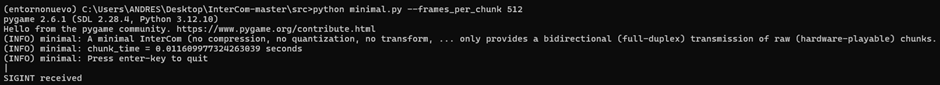

#### Conclusiones Extraídas:
* **Variación de Latencia:** Al reducir el parámetro `--frames_per_chunk` a 512, la latencia estructural teórica disminuye a la mitad (11.61 ms). Experimentalmente, la latencia acústica percibida con los auriculares cae notablemente, situándose en un rango casi instantáneo (estimado en unos 30-40 ms), lo que mejora drásticamente la inmediatez de la conversación.
* **Impacto en Calidad:** A pesar de trabajar con bloques más pequeños, la calidad de sonido se mantiene limpia y no se aprecian cortes o distorsiones, ya que el procesador de la máquina es capaz de gestionar el doble de bloques por segundo sin saturarse.
* **Límites Físicos:** Si se redujera aún más (por ejemplo, a 128 o 64), la latencia sería mínima pero el audio empezaría a sufrir micro-cortes (*buffer underrun*) porque la tarjeta de sonido de Windows no lograría procesar las interrupciones tan rápido.


### Experimento 3: Variación de la tasa de muestreo (`--frames_per_second`)
**Enunciado:** Modifica el parámetro `--frames_per_second`. De nuevo, ¿notas algún cambio en la latencia o en la calidad del audio? Determina la nueva latencia. Determina también la frecuencia máxima que capturarás (en función del parámetro frames_per_second).


### Reducción de la tasa de muestreo a 16000 hercios:
##### python minimal.py --frames_per_second 16000


#### Conclusiones Extraídas:
* **Variación de la Latencia (Retraso):** Al reducir el parámetro `--frames_per_second` a 16000, la latencia estructural teórica sube drásticamente a 64 ms (casi el triple que al principio). En la práctica, al realizar la prueba acústica del aplauso, se percibe un retraso muy evidente y molesto (eco de más de 120-150 ms), haciendo que la conversación ya no se sienta totalmente en tiempo real.
* **Impacto en la Calidad del Audio:** La calidad del sonido disminuye notablemente. El audio se percibe más opaco, apagado o "telefónico". Esto ocurre porque al reducir la tasa de muestreo estamos perdiendo los componentes de alta frecuencia (los sonidos más agudos) de la voz.
* **Cálculo de la Frecuencia Máxima (Teorema de Nyquist):** Siguiendo el Teorema de Nyquist, la frecuencia máxima de sonido que el sistema puede capturar y reproducir digitalmente sin aliasing es exactamente la mitad de la tasa de muestreo. Por tanto:

$$f_{\text{max}} = \frac{\text{frames per second}}{2} = \frac{16000}{2} = 8000 \text{ Hz (8 kHz)}$$

Como el oído humano escucha hasta los 20000 Hz, al limitar el sistema a 8000 Hz eliminamos gran parte de los agudos, lo que explica científicamente por qué el audio suena opaco.


### Experimento 4: Conexión en la misma red LAN
**Enunciado:** Con uno de tus compañeros de grupo, intenta comunicarte utilizando la misma red LAN (tendrás que modificar el parámetro `--destination_address`). Ten en cuenta que algunas redes LAN, como la proporcionada por la UAL, podrían filtrar tu tráfico de InterCom. Buenas opciones alternativas son la red LAN de tu casa o una red LAN ad-hoc creada con un teléfono móvil. Determina la nueva latencia.


### Experimento 5: Transmisión de fragmentos
**Enunciado:** Repite el último experimento cuando dos (o más) compañeros de grupo te transmitan sus fragmentos. ¿Qué está sucediendo?

### Experimento 6: Conexión distinta red LAN
**Enunciado:** Por último, ¿eres capaz de comunicarte con un interlocutor que se encuentra en una red LAN diferente a la tuya (por ejemplo, cuando dos instancias de InterCom se ejecutan en redes domésticas distintas)? Describe el experimento, incluso si no funciona. Presta también atención a la calidad del audio, si logras comunicarte. ¿Cuál es la latencia ahora? 
